# 🔍 Lab 02: Failure Clustering and Categorization

## Module 02 — Failure Mode Analysis 🐛

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/varoonsahgal/adv-model-eval-student/blob/main/labs/02-failure-analysis-lab.ipynb)

| | |
|---|---|
| ⏱️ **Time** | 20–25 min hands-on |
| 🎚️ **Level** | Intermediate: light pandas + scikit-learn |
| 🔑 **Accounts / keys** | None. Runs fully offline after a one-time ~90 MB model download |
| 🧰 **You'll use** | `sentence-transformers` · `scikit-learn` (K-Means, PCA) · `pandas` · `matplotlib` |
| 🏁 **You'll leave with** | A labelled, impact-ranked map of 30 production failures |

---

## 🧭 Overview

In this lab, you will load a dataset of mixed AI system failures, compute embeddings, cluster failures, label clusters using the failure taxonomy, and identify high-impact patterns. You will practice the full workflow of going from raw failure data to actionable categories.

> 🎯 **Why This Matters:** In production AI systems, failures don't come with neat labels. You get messy logs, free-text descriptions, and angry tickets. This lab teaches you how to turn that chaos into a structured picture so you know *what* is going wrong and *where* to focus your effort.

### 🛠️ What You'll Build

By the end of this lab you will have:
- 📂 Loaded and explored a synthetic failure dataset
- 🤔 Predicted failure categories before seeing data patterns
- 🧮 Computed embeddings and clustered failures
- 🏷️ Labeled clusters using the failure taxonomy from the module
- 📊 Identified the highest-impact failure cluster
- 🧩 Investigated outlier failures that resist categorization

### The Failure Analysis Pipeline

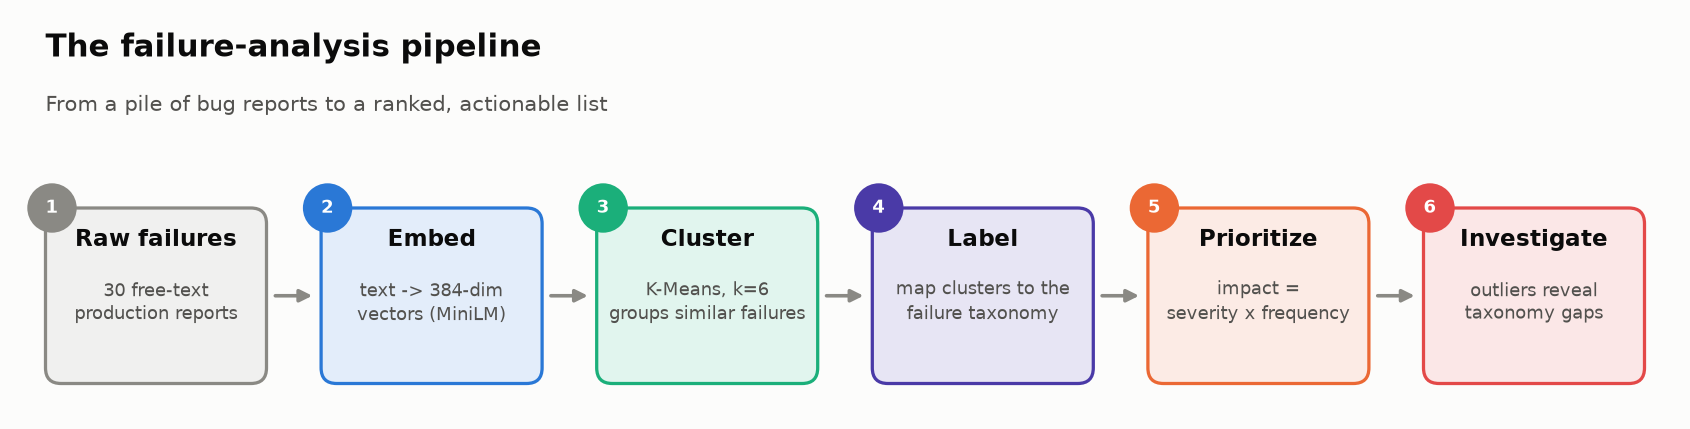

<sub>🖼️ *The pipeline you'll build: Task 2 loads, Task 4 embeds, Task 5 clusters, Task 6 labels, Task 7 prioritizes, Task 8 investigates*</sub>

## 🎯 Learning Objectives

1. Apply a failure taxonomy to categorize AI system failures
2. Use embeddings to cluster similar failures
3. Identify long-tail failures that surface-level metrics miss
4. Prioritize failures by impact and frequency

## 📋 Prerequisites

- Module 01 completed (Modern AI Evaluation Foundations)
- Basic understanding of embeddings and vector similarity
- Python proficiency (pandas, sklearn basics)

## ⏱️ Estimated Time

**20–25 minutes** hands-on

## 🎬 Scenario

You are an ML engineer responsible for improving an AI-powered customer support assistant. Over the past week, the QA team has flagged 30 failures from production logs. Your job is to make sense of these failures systematically — not by reading each one individually, but by clustering them into categories, labeling the clusters, and figuring out which failure pattern deserves the most attention.

Management doesn't want a list of 30 bugs. They want to know: *What kinds of things are going wrong, and which kind matters most?*

---

## Task 1: Environment Setup and Dependencies ⚙️

### Goal
Install the required packages for embeddings, clustering, and visualization.

### Why These Libraries?

| Library | What It Does in This Lab |
|---------|--------------------------|
| `sentence-transformers` | Converts text into numerical vectors (embeddings) so we can measure similarity |
| `scikit-learn` | Provides K-Means clustering and PCA for dimensionality reduction |
| `pandas` | Organizes our failure data into tables we can easily filter and analyze |
| `matplotlib` / `plotly` | Creates charts to visualize clusters and impact scores |

### Steps
Run the cell below to install all dependencies. This may take 1–2 minutes.

In [ ]:
%%capture
# Install required packages (output is hidden by %%capture to keep things clean)
# sentence-transformers: turns text into numerical vectors for similarity comparison
# scikit-learn: provides clustering (KMeans) and dimensionality reduction (PCA)
# pandas: data manipulation (tables, filtering, grouping)
# matplotlib & plotly: charting and visualization
!pip install sentence-transformers scikit-learn pandas matplotlib plotly

In [ ]:
import pandas as pd                          # DataFrames for tabular data manipulation
import numpy as np                           # Numerical operations on arrays
from sentence_transformers import SentenceTransformer  # Converts text → embedding vectors
from sklearn.cluster import KMeans           # Groups similar embeddings into clusters
from sklearn.decomposition import PCA        # Reduces high-dimensional embeddings to 2D for plotting
import matplotlib.pyplot as plt              # Creates static charts and scatter plots

print("✅ All imports successful.")

### Checkpoint ✅
You should see `✅ All imports successful.` above with no errors. If you see a `ModuleNotFoundError`, re-run the install cell and restart the kernel.

> 💡 **Tip:** If you restart the kernel later, you'll need to re-run these first two cells to reload the libraries.

---
**Next up:** Now that our tools are ready, let's load the failure data we'll be analyzing. ➡️

---

## Task 2: Load the Failure Dataset 📂

### Goal
Load a synthetic dataset of 30 AI system failures from production logs. Each failure has a description, severity level, and whether it was user-facing.

### Why Start Here?
Before we can cluster or categorize anything, we need data. In the real world, failure data comes from production logs, QA reports, user complaints, or trace analysis. Here we use a curated synthetic dataset so you can focus on the *method* rather than data wrangling.

> 💡 **Key Insight:** Each failure record has both a free-text `description` (what went wrong) and structured metadata (`severity`, `frequency`, `user_facing`). The description is what we'll embed and cluster; the metadata is what we'll use later to prioritize.

### Steps
Run the cell below to create the failure dataset.

In [ ]:
# =============================================================================
# Synthetic failure dataset — 30 production failures from a customer support AI
# Each failure has: id, description (free text), severity, user_facing flag, frequency
#
# The failures are intentionally grouped into 6 hidden categories:
#   - Boundary errors, Unsupported claims, Incomplete outputs,
#   - Tool misuse, Planning failures, Execution failures
# ...but the code below doesn't label them. That's YOUR job later!
# =============================================================================

failures = [
    # --- Boundary errors: inputs at edge of training distribution ---
    {"id": 1, "description": "User asked question in mixed French and English; assistant responded entirely in English, ignoring French portions", "severity": "medium", "user_facing": True, "frequency": 12},
    {"id": 2, "description": "User pasted a 15,000-word legal contract and asked for a summary; assistant returned a generic one-sentence response", "severity": "high", "user_facing": True, "frequency": 5},
    {"id": 3, "description": "User input contained special Unicode characters (emojis, mathematical symbols); response was garbled with encoding errors", "severity": "medium", "user_facing": True, "frequency": 8},
    {"id": 4, "description": "User sent an extremely short ambiguous query ('help'); assistant gave an irrelevant boilerplate response about account setup", "severity": "low", "user_facing": True, "frequency": 25},
    {"id": 5, "description": "User asked about a product feature released yesterday; assistant confidently described the old version of the feature", "severity": "high", "user_facing": True, "frequency": 15},
    
    # --- Unsupported claims: hallucinations and fabrications ---
    {"id": 6, "description": "Assistant cited a non-existent support article (Article KB-4892) when answering a billing question", "severity": "high", "user_facing": True, "frequency": 18},
    {"id": 7, "description": "Assistant stated the company offers a 90-day money-back guarantee; actual policy is 30 days", "severity": "critical", "user_facing": True, "frequency": 7},
    {"id": 8, "description": "Assistant fabricated a phone number for the support team that doesn't exist", "severity": "critical", "user_facing": True, "frequency": 3},
    {"id": 9, "description": "Assistant claimed the enterprise plan includes unlimited API calls; actual limit is 100K/month", "severity": "critical", "user_facing": True, "frequency": 10},
    {"id": 10, "description": "Assistant invented a feature called 'Smart Auto-Routing' that does not exist in the product", "severity": "high", "user_facing": True, "frequency": 6},
    
    # --- Incomplete outputs: missing required information ---
    {"id": 11, "description": "User asked for step-by-step setup instructions; assistant provided steps 1-3 but stopped mid-sentence before completing step 4 of 6", "severity": "medium", "user_facing": True, "frequency": 20},
    {"id": 12, "description": "Assistant answered how to reset password but omitted the critical step of email verification", "severity": "high", "user_facing": True, "frequency": 14},
    {"id": 13, "description": "Response listed 3 pricing tiers but left out the enterprise tier that was most relevant to the user's question", "severity": "medium", "user_facing": True, "frequency": 9},
    {"id": 14, "description": "Assistant provided API integration code but omitted authentication headers, making the example non-functional", "severity": "high", "user_facing": True, "frequency": 11},
    {"id": 15, "description": "Response about data export mentioned CSV and JSON formats but omitted the XML option that the user specifically asked about", "severity": "medium", "user_facing": True, "frequency": 7},
    
    # --- Tool misuse: incorrect tool selection or parameters ---
    {"id": 16, "description": "Assistant invoked the billing API to answer a technical support question about API rate limits", "severity": "medium", "user_facing": False, "frequency": 16},
    {"id": 17, "description": "Assistant called the user lookup tool with an email address in the name field, returning zero results", "severity": "medium", "user_facing": True, "frequency": 13},
    {"id": 18, "description": "Assistant queried the knowledge base with the entire user message as a search query instead of extracting key terms", "severity": "low", "user_facing": False, "frequency": 30},
    {"id": 19, "description": "Assistant used the 'create ticket' tool when user only asked for ticket status, creating a duplicate ticket", "severity": "high", "user_facing": True, "frequency": 4},
    {"id": 20, "description": "Assistant called the product catalog API with a deprecated endpoint version, receiving stale pricing data", "severity": "high", "user_facing": True, "frequency": 8},
    
    # --- Planning failures: flawed reasoning or strategy ---
    {"id": 21, "description": "User asked to cancel and get a refund; assistant processed the cancellation first, then discovered the refund required the active subscription", "severity": "critical", "user_facing": True, "frequency": 2},
    {"id": 22, "description": "Assistant tried to resolve a complex billing dispute in a single step instead of breaking it into: verify charges, check policy, calculate adjustment", "severity": "medium", "user_facing": True, "frequency": 11},
    {"id": 23, "description": "Assistant asked the user for their account ID three separate times across the conversation because it didn't retain context between steps", "severity": "medium", "user_facing": True, "frequency": 19},
    {"id": 24, "description": "When user reported two separate issues, assistant conflated them into one and only addressed the second issue", "severity": "high", "user_facing": True, "frequency": 8},
    {"id": 25, "description": "Assistant recommended upgrading the user's plan to fix a bug that exists in all plan tiers", "severity": "high", "user_facing": True, "frequency": 5},
    
    # --- Execution failures: correct plan, incorrect execution ---
    {"id": 26, "description": "Assistant correctly identified the need to check order status but returned the status of a different customer's order due to ID parsing error", "severity": "critical", "user_facing": True, "frequency": 3},
    {"id": 27, "description": "Assistant correctly planned to apply a discount code but entered '10' as dollars-off instead of 10 percent, overcharging the customer", "severity": "critical", "user_facing": True, "frequency": 2},
    {"id": 28, "description": "Response formatting broke — bullet points rendered as raw markdown in the chat interface", "severity": "low", "user_facing": True, "frequency": 35},
    {"id": 29, "description": "Assistant generated the correct SQL query for the report but applied the wrong date filter (UTC vs local timezone), pulling an extra day of data", "severity": "medium", "user_facing": False, "frequency": 12},
    
    # --- Outlier: intentionally hard to categorize ---
    {"id": 30, "description": "Assistant became stuck in a loop, repeatedly asking 'Is there anything else I can help you with?' without ever addressing the original question about how to export data", "severity": "high", "user_facing": True, "frequency": 6},
]

# Convert list of dicts into a pandas DataFrame for easy manipulation
df = pd.DataFrame(failures)

# Quick summary of what we loaded
print(f"Loaded {len(df)} failure records.")
print(f"\nSeverity distribution:")
print(df["severity"].value_counts().to_string())        # Count of each severity level
print(f"\nUser-facing: {df['user_facing'].sum()} / {len(df)}")  # How many users actually saw

In [ ]:
# Preview the first 10 failures — scan the descriptions to get a feel for the data
# Notice: each failure is a free-text description. How would you group these by hand?
df[["id", "description", "severity", "user_facing", "frequency"]].head(10)

### Checkpoint ✅
You should see `Loaded 30 failure records.` along with a severity distribution and a preview table. and `User-facing: 27 / 30`. Each failure has an ID, description, severity level, user-facing flag, and weekly frequency count.

### Expected Output
```
Loaded 30 failure records.

Severity distribution:
high        11
medium      10
critical     6
low          3
...
```

### 🔍 What Just Happened?

You loaded 30 real-ish failure records into a DataFrame. Right now they're just a flat list — there's no structure, no categories, no priorities. That's the problem we'll solve in this lab.

**Key observation:** Notice how the failures are all free text. You can't just `GROUP BY` a column to find patterns — the descriptions are too varied. That's exactly why we'll need embeddings and clustering.

> ⚠️ **Common Mistake:** Don't skip reading the descriptions! Understanding what the data *looks like* before applying algorithms is critical. Algorithms don't replace understanding.

---
**Next up:** Before we let an algorithm group these failures, let's see how well *you* can do it by eye. ➡️

---

## Task 3: 🤔 Think First — Predict Failure Categories

### Goal
Before you run any clustering algorithm, read through the failure descriptions above and **predict** what categories of failure you think exist in this dataset.

### Why This Matters
In practice, you should always form a hypothesis before letting an algorithm tell you what's there. This prevents you from blindly accepting whatever clusters the algorithm produces and helps you evaluate if the clustering output is meaningful.

> 🎯 **Why This Matters:** If you skip this step, you'll have no way to judge whether the algorithm's clusters are good or garbage. Your human intuition is the benchmark against which you validate the machine's output.

### Instructions

1. Scroll back up and read through the failure descriptions in the dataset.
2. Spend **3–4 minutes** thinking about what groups you see.
3. Write your predicted categories in the cell below.

### Questions to Reason About

- How many distinct failure categories do you think exist?
- What would you name each category?
- Are there any failures that seem to overlap multiple categories?
- Are there any that don't fit neatly anywhere?

> **This is a challenge section.** Write your own predictions. There is no single correct answer — the goal is to form hypotheses you can validate with clustering.

---
**Next up:** After writing your predictions, we'll convert the failure descriptions into numbers (embeddings) so a clustering algorithm can group them. ➡️

### ✍️ Your Predictions

**Write your answers here** (double-click to edit this cell):

1. **How many categories?**

   *Your answer...*

2. **Category names and what's in each:**

   *Your answer...*

3. **Any failures that overlap or don't fit?**

   *Your answer...*

---
*Keep this cell — you will compare your predictions against the actual clusters later.*

---

## Task 4: Compute Embeddings 🧮

### Goal
Convert each failure description into a numerical vector (embedding) so we can measure similarity between failures and cluster them.

### Why Embeddings? Why Not Just Read Them?

With 30 failures, you *could* read them all. But imagine 3,000 — or 30,000. Embeddings let us automate the comparison:

```
 "Assistant fabricated a phone number"  ──▶  [0.12, -0.34, 0.87, ..., 0.05]  (384 numbers)
 "Assistant cited a non-existent article" ──▶  [0.11, -0.31, 0.85, ..., 0.06]  (384 numbers)
                                                   ▲ These vectors are CLOSE together
                                                     because the meanings are similar!
```

> 💡 **Key Insight:** Embedding models are trained on massive text corpora. They learn that "fabricated a phone number" and "cited a non-existent article" are *semantically similar* (both are hallucinations) — even though they share few words in common. This is far more powerful than keyword matching.

### Steps
1. Load a lightweight sentence-transformer model
2. Encode all failure descriptions into 384-dimensional vectors
3. Inspect the embedding shape

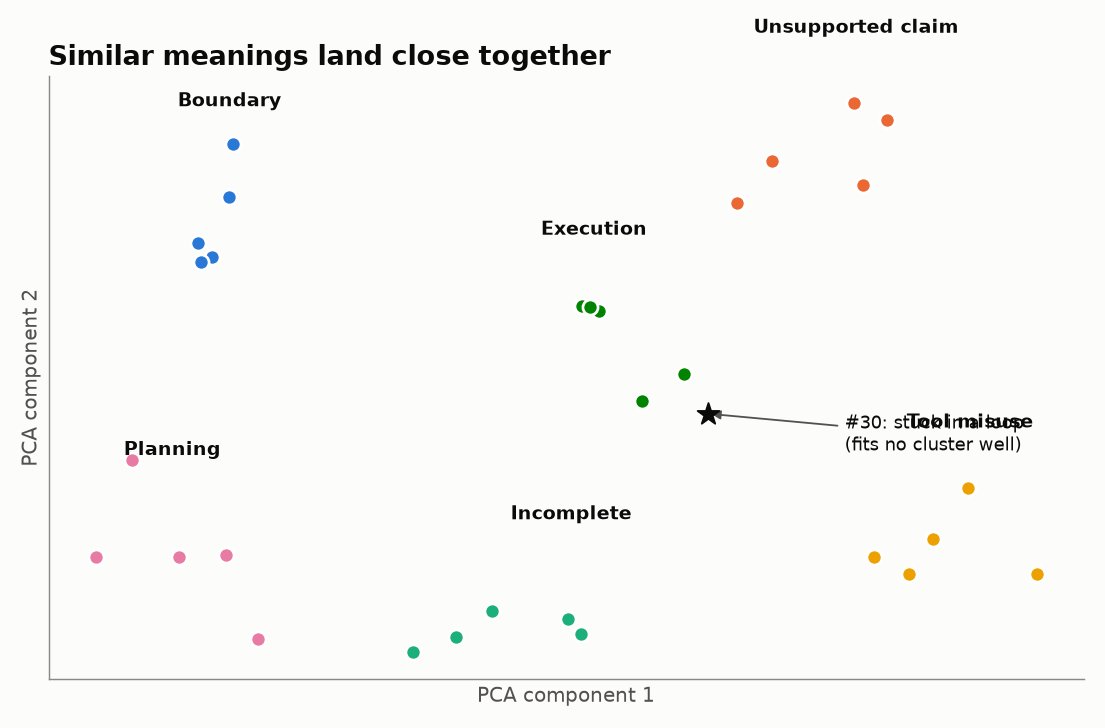

<sub>🖼️ *Illustration: embeddings place similar failure descriptions near each other, so clusters emerge*</sub>

In [ ]:
# Load a lightweight embedding model
# "all-MiniLM-L6-v2" is a small, fast model that converts sentences into 384-dim vectors.
# It's not the most powerful model, but it's great for clustering short texts like ours.
model = SentenceTransformer("all-MiniLM-L6-v2")
print(f"✅ Model loaded: all-MiniLM-L6-v2")

# Extract the text descriptions from our DataFrame into a plain Python list
descriptions = df["description"].tolist()

# Compute embeddings: each text description → a 384-dimensional numerical vector
# The model reads each sentence and outputs a fixed-size vector that captures its meaning.
# Similar meanings → vectors that are close together in 384-dimensional space.
embeddings = model.encode(descriptions, show_progress_bar=True)

# Check the shape: should be (30, 384) — 30 failures, each as a 384-dim vector
print(f"\nEmbedding shape: {embeddings.shape}")
print(f"Each failure is now a {embeddings.shape[1]}-dimensional vector.")

### Checkpoint ✅
You should see:
- `✅ Model loaded: all-MiniLM-L6-v2`
- `Embedding shape: (30, 384)` — 30 failures, each represented as a 384-dimensional vector

If you get a download progress bar for the model, that's normal on first run.

### 🔍 What Just Happened?

We just converted 30 free-text failure descriptions into 30 numerical vectors (each with 384 numbers). This is the key transformation that makes clustering possible:

```
BEFORE: "Assistant fabricated a phone number..."  (text — hard to compare mathematically)
AFTER:  [0.12, -0.34, 0.87, ..., 0.05]           (vector — easy to compare with math!)
```

**Why 384 dimensions?** That's the architecture of this particular model. Each dimension captures some aspect of meaning. You don't need to interpret individual dimensions — what matters is that similar texts produce similar vectors.

> 💡 **Key Insight:** Embeddings are the bridge between human language and mathematical algorithms. Without this step, clustering algorithms can't operate on text.

---
**Next up:** Now that we have numbers, let's let K-Means find natural groupings. ➡️

---

## Task 5: Cluster Failures 🔬

### Goal
Use K-Means clustering to group the 30 failure cases into clusters based on their embedding similarity.

### Why K-Means?
K-Means is a simple, widely-used clustering algorithm. You tell it how many groups (`k`) you want, and it partitions the data so that items within each group are as similar as possible.

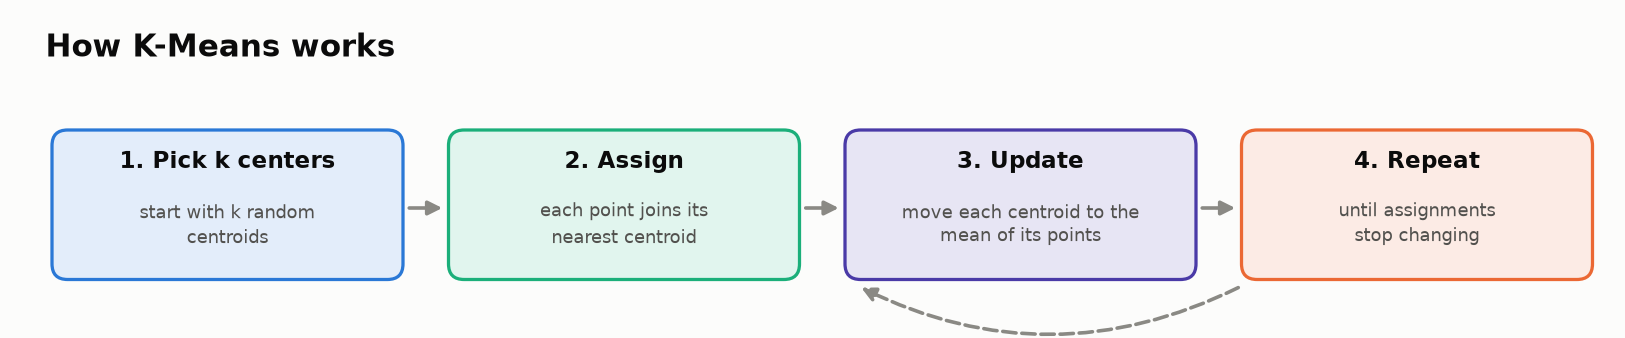

<sub>🖼️ *K-Means in four steps*</sub>

> ⚠️ **Common Mistake:** K-Means requires you to choose `k` upfront. We're using `k=6` because our taxonomy has 6 categories — but in real scenarios, you might need to experiment with different values of k.

### Steps
1. Run K-Means with `k=6` (matching the 6 categories in the failure taxonomy)
2. Assign cluster labels to each failure
3. Visualize clusters using PCA for dimensionality reduction

In [ ]:
# Run K-Means clustering with k=6 (we expect ~6 failure categories from our taxonomy)
# n_clusters=6: create 6 groups
# random_state=42: makes results reproducible (same clusters each run)
# n_init=10: run the algorithm 10 times with different starting points, keep the best
kmeans = KMeans(n_clusters=6, random_state=42, n_init=10)

# fit_predict() does two things:
#   1. Learns the cluster centers from the embedding data
#   2. Assigns each failure to its nearest cluster (0, 1, 2, 3, 4, or 5)
df["cluster"] = kmeans.fit_predict(embeddings)

# Show how many failures landed in each cluster
print("Cluster assignment counts:")
print(df["cluster"].value_counts().sort_index().to_string())
print(f"\nTotal: {len(df)} failures across {df['cluster'].nunique()} clusters")

In [ ]:
# =============================================================================
# Visualize clusters using PCA (Principal Component Analysis)
#
# Problem: Our embeddings are 384-dimensional — we can't plot 384 axes!
# Solution: PCA squashes 384 dimensions down to 2 while preserving as much
#           structure as possible. This is ONLY for visualization — the actual
#           clustering was done in the full 384D space.
# =============================================================================

pca = PCA(n_components=2, random_state=42)         # Reduce to 2 dimensions
coords = pca.fit_transform(embeddings)              # Transform 384D → 2D
df["x"] = coords[:, 0]                              # First PCA component (x-axis)
df["y"] = coords[:, 1]                              # Second PCA component (y-axis)

# Create a scatter plot: each dot is a failure, colored by cluster
plt.figure(figsize=(10, 7))
scatter = plt.scatter(
    df["x"], df["y"],           # Plot position from PCA
    c=df["cluster"],            # Color by cluster assignment
    cmap="tab10",               # Use a color palette with distinct colors
    s=100,                      # Dot size
    edgecolors="black",         # Black border around each dot for clarity
    linewidth=0.5,
    alpha=0.8                   # Slight transparency
)

# Label each point with its failure ID so you can identify individual failures
for _, row in df.iterrows():
    plt.annotate(
        str(row["id"]),                    # The label text (failure ID number)
        (row["x"], row["y"]),              # Position of the label
        textcoords="offset points",
        xytext=(5, 5),                     # Slight offset so labels don't overlap dots
        fontsize=8
    )

plt.colorbar(scatter, label="Cluster")
plt.title("Failure Clusters (PCA Projection)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.tight_layout()
plt.show()

### Checkpoint ✅
You should see:
- A count table showing how many failures fell into each cluster (0–5)
- A scatter plot with color-coded clusters and failure IDs annotated

The clusters may not perfectly match the taxonomy categories — that's normal and part of the learning. PCA is just for visualization; the actual clustering happens in the full 384-dimensional space.

> 💡 **Key Insight:** If some dots of different colors appear close together on the plot, remember: PCA compresses 384 dimensions into 2. Points that look close in 2D might actually be far apart in the full space. Trust the cluster assignments, not the visual proximity.

### 🔍 What Just Happened?

We just went from 30 individual failure vectors to **6 groups of similar failures**. The algorithm found natural groupings based purely on the *meaning* of the descriptions — no labels, no rules, just similarity.

```
Before clustering:   30 individual, unlabeled failures
After clustering:    6 groups, each containing failures that "sound alike"
```

> 💡 **Key Insight:** Clustering reveals patterns that are invisible when reading failures one at a time. You might never notice that 5 different failures are all about "hallucinated information" unless you group them.

---
**Next up:** Now we'll look inside each cluster to see what's actually in there, and then YOU will label them. ➡️

In [ ]:
# Print the failures within each cluster so you can read and label them
# This is the critical step where YOU inspect the algorithm's output
for cluster_id in sorted(df["cluster"].unique()):
    cluster_df = df[df["cluster"] == cluster_id]  # Filter to just this cluster's failures
    print(f"\n{'='*80}")
    print(f"CLUSTER {cluster_id} ({len(cluster_df)} failures)")
    print(f"{'='*80}")
    for _, row in cluster_df.iterrows():
        # Severity emoji coding: 🔴 critical, 🟠 high, 🟡 medium, 🟢 low
        severity_marker = {"critical": "🔴", "high": "🟠", "medium": "🟡", "low": "🟢"}
        marker = severity_marker.get(row["severity"], "⚪")
        # Truncate long descriptions to keep the output readable
        desc = row['description'][:100] + "..." if len(row['description']) > 100 else row['description']
        print(f"  {marker} [{row['id']:2d}] {desc}")

---

## Task 6: 🧠 Your Turn — Label Clusters Using the Failure Taxonomy

### Goal
Now comes the critical thinking step. You need to examine each cluster and assign a label from the **failure taxonomy** you learned in the module.

### The Failure Taxonomy (Reference)

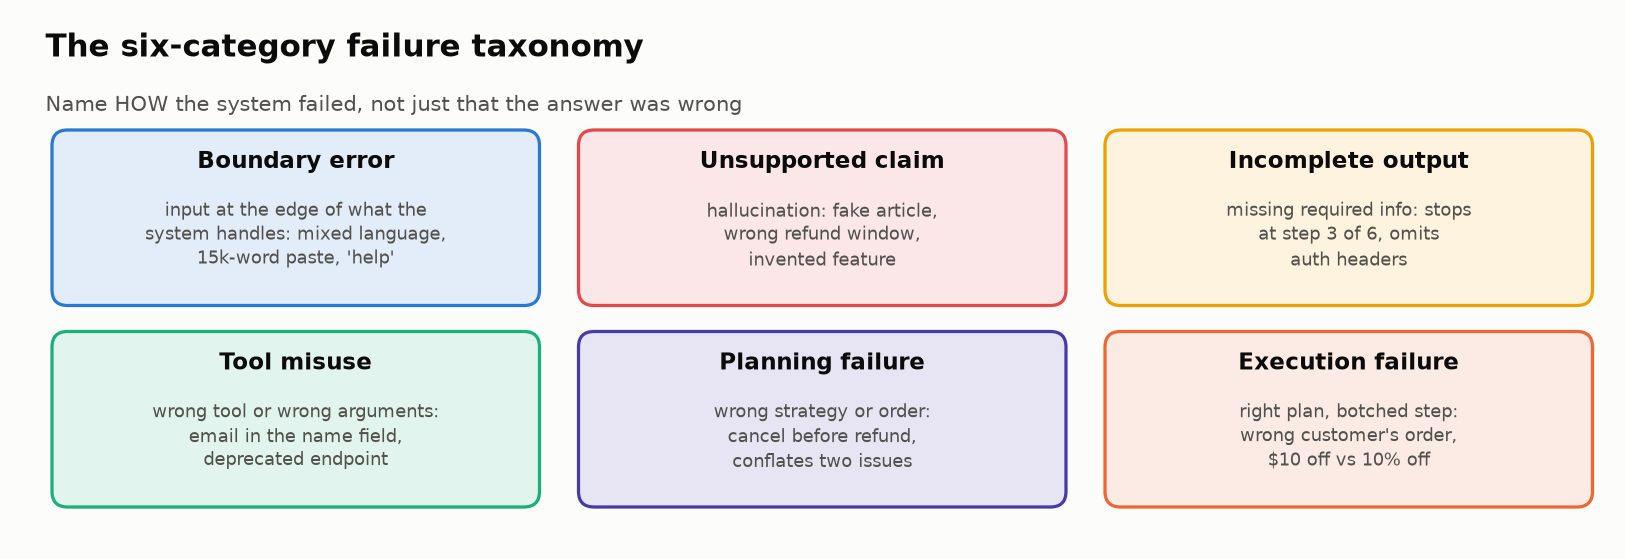

<sub>🖼️ *The six failure categories, with examples from this dataset*</sub>

| Category | Description | Example Pattern |
|----------|-------------|-----------------|
| **Boundary Error** | Inputs at edge of training distribution | unusual formats, languages, lengths |
| **Unsupported Claim** | Hallucinations and fabrications | fake facts, wrong numbers, invented features |
| **Incomplete Output** | Missing required information | truncated steps, omitted details |
| **Tool Misuse** | Incorrect tool selection or wrong parameters | wrong API, bad field mapping |
| **Planning Failure** | Flawed reasoning or strategy | wrong order of operations, missed context |
| **Execution Failure** | Correct plan but incorrect execution | right idea, wrong implementation |

### Instructions

1. Read through the cluster printout above carefully
2. For each cluster (0–5), decide which taxonomy category best fits
3. Fill in the `cluster_labels` dictionary in the code cell below
4. Write a brief justification for each label

> ⚠️ **Common Mistake:** Don't blindly trust cluster labels — always validate against the data. If a cluster contains a mix of categories, choose the **best fit** and note the exceptions.

**Hint:** Not every cluster will map perfectly to one taxonomy category. Some clusters may contain a mix. Choose the **best fit** and note any items that seem like they belong elsewhere.

> **This is a challenge section.** You must decide the labels yourself based on the data. There is no single correct mapping — it depends on how the embeddings clustered the descriptions.

In [ ]:
# =============================================================================
# 🧠 YOUR TURN: Label each cluster with the taxonomy category that best fits
#
# Look at the cluster printout above. For each cluster (0-5), replace "???"
# with the taxonomy label that best describes the failures in that cluster.
#
# Valid labels:
#   "Boundary Error", "Unsupported Claim", "Incomplete Output",
#   "Tool Misuse", "Planning Failure", "Execution Failure"
# =============================================================================

cluster_labels = {
    0: "???",   # Look at the failures in Cluster 0 — which category fits best?
    1: "???",   # Look at the failures in Cluster 1 — which category fits best?
    2: "???",   # Look at the failures in Cluster 2 — which category fits best?
    3: "???",   # Look at the failures in Cluster 3 — which category fits best?
    4: "???",   # Look at the failures in Cluster 4 — which category fits best?
    5: "???",   # Look at the failures in Cluster 5 — which category fits best?
}

# Apply your labels to the DataFrame so each failure gets a taxonomy_label column
df["taxonomy_label"] = df["cluster"].map(cluster_labels)

# Print a summary of your labeling
print("Your labeled clusters:\n")
for cluster_id in sorted(df["cluster"].unique()):
    label = cluster_labels[cluster_id]
    count = len(df[df["cluster"] == cluster_id])
    print(f"  Cluster {cluster_id}: {label} ({count} failures)")

### ✍️ Your Justifications

**Write a 1–2 sentence justification for each label** (double-click to edit):

- **Cluster 0:**  *Your justification...*
- **Cluster 1:**  *Your justification...*
- **Cluster 2:**  *Your justification...*
- **Cluster 3:**  *Your justification...*
- **Cluster 4:**  *Your justification...*
- **Cluster 5:**  *Your justification...*

**Any items that seem misclustered?** Note their IDs and where you think they should go:

*Your observations...*

---

Now compare your cluster labels with your **predictions from Task 3**. How close were you?

> 💡 **Key Insight:** If your predictions were close, great — your intuition aligns with the algorithm. If they were different, that's also valuable: either the algorithm found something you missed, or it grouped things in a way that doesn't quite match reality. Both outcomes teach you something.

---
**Next up:** We know *what kinds* of failures exist. Now let's figure out *which kind matters most*. ➡️

---

## Task 7: Identify the Highest-Impact Cluster 📊

### Goal
Determine which failure cluster deserves the most attention by combining severity and frequency into an impact score.

### Why Impact Scoring?
Not all failures are equal. Consider:
- A **critical** failure that happens **2×/week** = serious but rare
- A **medium** failure that happens **30×/week** = less severe but very frequent

Which one should you fix first? Impact scoring gives you a principled way to decide.

```
Impact Score = Severity Weight × Weekly Frequency

Example:
  Critical (weight=5) × 2/week  = 10 impact points
  Medium   (weight=2) × 30/week = 60 impact points  ← This one wins!
```

> 🎯 **Why This Matters:** Without impact scoring, teams tend to fix whichever bug was reported last, or whichever seems scariest. Impact scoring replaces gut feelings with data.

### Steps
1. Compute an impact score for each failure: `severity_weight × frequency`
2. Aggregate impact by cluster
3. Identify the highest-impact cluster

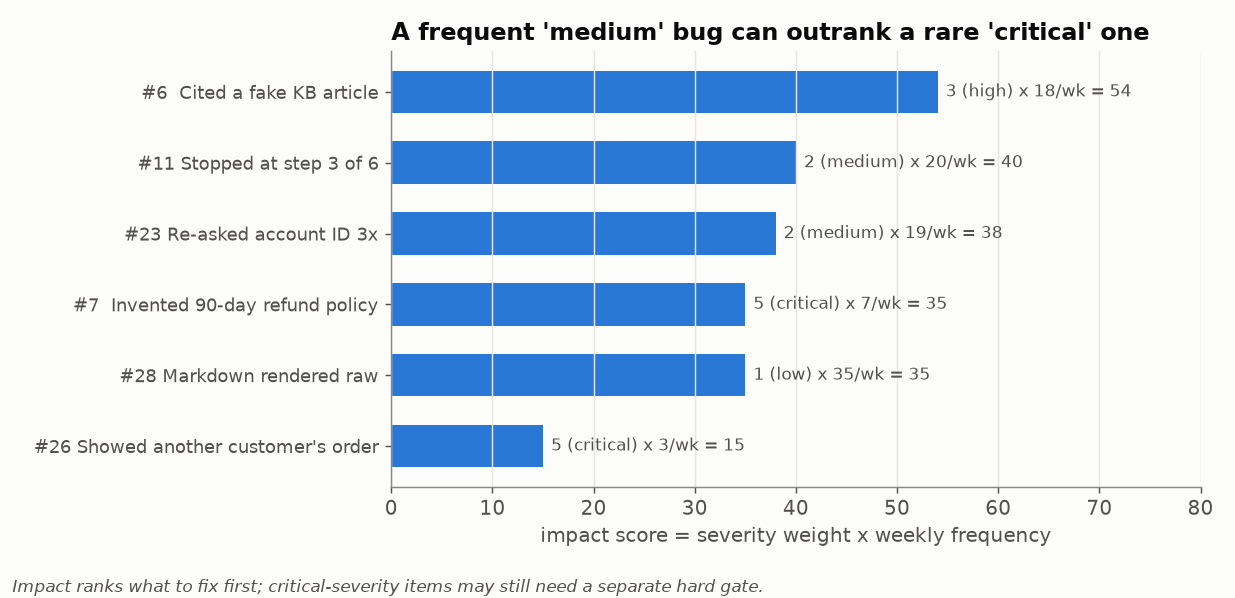

<sub>🖼️ *Impact scores for six of the 30 failures: frequency can outweigh severity*</sub>

In [ ]:
# Define severity weights — higher weight means the failure is more damaging
# These weights are a judgment call; in practice, your team would calibrate them
severity_weights = {"low": 1, "medium": 2, "high": 3, "critical": 5}

# Map each failure's severity string to its numerical weight
df["severity_weight"] = df["severity"].map(severity_weights)

# Compute impact score: severity_weight × frequency
# A critical failure (5) happening 10×/week = 50 impact points
# A low failure (1) happening 35×/week = 35 impact points
df["impact_score"] = df["severity_weight"] * df["frequency"]

# Show the top 10 individual failures by impact score
print("Individual failure impact scores (top 10):\n")
top_failures = df.nlargest(10, "impact_score")[["id", "description", "severity", "frequency", "impact_score", "taxonomy_label"]]
for _, row in top_failures.iterrows():
    desc_short = row["description"][:70] + "..." if len(row["description"]) > 70 else row["description"]
    print(f"  [{row['id']:2d}] Impact={row['impact_score']:3d}  ({row['severity']}, freq={row['frequency']})  {desc_short}")

In [ ]:
# Aggregate impact scores by cluster — this tells us which CATEGORY is most impactful
# We group by cluster and compute several summary statistics:
cluster_impact = df.groupby("cluster").agg(
    label=("taxonomy_label", "first"),                            # The label you assigned
    total_impact=("impact_score", "sum"),                         # Sum of all impact scores in cluster
    avg_impact=("impact_score", "mean"),                          # Average impact per failure
    failure_count=("id", "count"),                                # How many failures in this cluster
    critical_count=("severity", lambda x: (x == "critical").sum()),  # How many are critical
    total_frequency=("frequency", "sum"),                         # Total weekly occurrences
).sort_values("total_impact", ascending=False)  # Sort: highest-impact cluster first

print("\n📊 Cluster Impact Rankings:\n")
print(cluster_impact.to_string())

# Identify the #1 highest-impact cluster
top_cluster = cluster_impact.index[0]
top_label = cluster_impact.iloc[0]["label"]
top_impact = cluster_impact.iloc[0]["total_impact"]
print(f"\n🎯 Highest-impact cluster: Cluster {top_cluster} ({top_label}) — total impact score: {top_impact}")

In [ ]:
# =============================================================================
# Visualize cluster impact with two side-by-side charts
# Left:  Total impact score per cluster (horizontal bar chart)
# Right: Frequency vs Severity for all 30 failures (scatter plot, bubble size = impact)
# =============================================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Chart 1: Total Impact by Cluster (bar chart) ---
colors = plt.cm.tab10(range(len(cluster_impact)))
axes[0].barh(
    [f"C{idx}: {row['label']}" for idx, row in cluster_impact.iterrows()],  # Cluster labels
    cluster_impact["total_impact"],   # Bar length = total impact
    color=colors
)
axes[0].set_xlabel("Total Impact Score")
axes[0].set_title("Total Impact by Cluster")
axes[0].invert_yaxis()  # Highest-impact cluster at the top

# --- Chart 2: Frequency vs Severity scatter (each dot = one failure) ---
scatter = axes[1].scatter(
    df["frequency"],          # X-axis: how often does this failure happen?
    df["severity_weight"],    # Y-axis: how severe is it?
    c=df["cluster"],          # Color: which cluster does it belong to?
    cmap="tab10",
    s=df["impact_score"] * 3, # Bubble size proportional to impact score
    edgecolors="black",
    linewidth=0.5,
    alpha=0.7
)
# Label each bubble with its failure ID
for _, row in df.iterrows():
    axes[1].annotate(str(row["id"]), (row["frequency"], row["severity_weight"]),
                     textcoords="offset points", xytext=(4, 4), fontsize=7)
axes[1].set_xlabel("Weekly Frequency")
axes[1].set_ylabel("Severity Weight")
axes[1].set_yticks([1, 2, 3, 5])
axes[1].set_yticklabels(["Low", "Medium", "High", "Critical"])
axes[1].set_title("Frequency vs Severity (size = impact)")

plt.tight_layout()
plt.show()

### Checkpoint ✅
You should see:
- A ranked table of clusters by total impact
- The highest-impact cluster identified with a 🎯
- Two charts: total impact by cluster (left) and a frequency-vs-severity scatter plot (right)

### Expected Insight
The highest-impact cluster will likely include failures that are either very frequent or very severe (or both). This is the cluster your team should tackle first.

### 🔍 What Just Happened?

We went from "here are 6 clusters" to "**this cluster is the most important to fix**." That's the whole point of failure mode analysis — turning a pile of bugs into a prioritized action plan.

```
Pipeline so far:
  Raw failures → Embeddings → Clusters → Labels → ✅ PRIORITIES

You started with 30 messy failures.
You now have a ranked list of failure categories to fix, in order of impact.
That's what you present to management.
```

> 🎯 **Why This Matters:** In the real world, engineering teams have limited time. You can't fix everything at once. Impact scoring tells you where your effort will have the biggest payoff.

---
**Next up:** One last challenge — what about failures that don't fit *any* category? ➡️

---

## Task 8: 🧩 Debug — Investigate the Outlier

### Goal
Failure #30 (the looping assistant) is intentionally hard to categorize. Your job is to investigate it, determine why it doesn't fit neatly into a cluster, and decide where it belongs.

### Context
In real-world failure analysis, not every failure fits a clean category. Outliers are important — they can reveal **new failure modes** your taxonomy doesn't yet cover, or failures that span multiple categories.

```
Most failures:   fit neatly into one taxonomy category  ✓
Some failures:   could belong to 2+ categories          ⚠️
Rare failures:   don't fit ANY category                 🧩 ← This is what we're investigating
```

> 🎯 **Why This Matters:** If you ignore outliers, you'll miss emerging failure patterns. The failures that don't fit your taxonomy today might become a whole new category tomorrow.

### Instructions

1. Run the cells below to identify which cluster failure #30 was assigned to
2. Check how similar it is to its cluster neighbors vs. other clusters
3. Answer the analysis questions

> **This is a challenge section.** You need to reason about what makes this failure different and decide how to handle it.

In [ ]:
# Find where failure #30 was assigned by the clustering algorithm
outlier = df[df["id"] == 30].iloc[0]             # Get the row for failure #30
outlier_cluster = outlier["cluster"]               # Which cluster did K-Means put it in?
outlier_embedding = embeddings[29]                 # Its embedding vector (index 29 for ID 30)

print(f"Failure #30: {outlier['description']}")
print(f"\nAssigned to: Cluster {outlier_cluster} ({cluster_labels.get(outlier_cluster, '???')})")
print(f"Severity: {outlier['severity']}, Frequency: {outlier['frequency']}/week")

In [ ]:
# Compute how similar failure #30's embedding is to each cluster's centroid
# Cosine similarity: 1.0 = identical directions, 0.0 = unrelated, -1.0 = opposite
from sklearn.metrics.pairwise import cosine_similarity

print("Similarity of Failure #30 to each cluster centroid:\n")
for cluster_id in sorted(df["cluster"].unique()):
    cluster_mask = df["cluster"] == cluster_id          # Boolean mask for this cluster
    centroid = embeddings[cluster_mask].mean(axis=0)    # Average embedding = cluster center
    sim = cosine_similarity([outlier_embedding], [centroid])[0][0]  # Compare #30 to centroid
    assigned = " ← assigned here" if cluster_id == outlier_cluster else ""
    print(f"  Cluster {cluster_id} ({cluster_labels.get(cluster_id, '???'):20s}): similarity = {sim:.4f}{assigned}")

# Also show how similar #30 is to individual failures in its assigned cluster
# Low similarity to neighbors = weak fit = potential outlier
print(f"\nNearest neighbors in Cluster {outlier_cluster}:")
cluster_mask = df["cluster"] == outlier_cluster
cluster_indices = df[cluster_mask].index.tolist()
for idx in cluster_indices:
    if idx == 29:  # Skip comparing #30 to itself (similarity would be 1.0)
        continue
    sim = cosine_similarity([outlier_embedding], [embeddings[idx]])[0][0]
    print(f"  [{df.loc[idx, 'id']:2d}] similarity = {sim:.4f} — {df.loc[idx, 'description'][:70]}...")

### ✍️ Outlier Analysis

**Answer these questions** (double-click to edit this cell):

1. **Does failure #30 belong in its assigned cluster?** Why or why not?

   *Your answer...*

2. **Which taxonomy category best fits failure #30?** (Could it be a mix?)

   *Your answer...*

3. **Does this failure suggest the taxonomy is missing a category?** If so, what would you call it?

   *Your answer...*

4. **In a real system, how would you handle failures that don't fit your taxonomy?**

   *Your answer...*

**Hint:** Think about whether this is a planning problem (bad strategy), an execution problem (right strategy, bad execution), or something else entirely (e.g., a system-level behavior like infinite loops).

---

## ✅ Validation / Success Criteria

You have successfully completed this lab if:

- ✅ **Task 1:** Environment set up, all imports successful
- ✅ **Task 2:** Loaded and explored the 30-failure dataset
- ✅ **Task 3:** Wrote predictions about failure categories **before** clustering
- ✅ **Task 4:** Computed embeddings (shape: 30 × 384)
- ✅ **Task 5:** Ran K-Means clustering and visualized the scatter plot
- ✅ **Task 6:** Labeled each cluster with a taxonomy category and justified your choices
- ✅ **Task 7:** Identified the highest-impact cluster using impact scoring
- ✅ **Task 8:** Investigated the outlier failure and reasoned about taxonomy gaps

> 🎉 **Congratulations!** You've completed the full failure analysis pipeline: from raw text → embeddings → clusters → labels → priorities → outlier investigation.

---

## Troubleshooting

| Symptom | Likely Cause | Fix |
|---------|-------------|-----|
| `ModuleNotFoundError: No module named 'sentence_transformers'` | Package not installed | Re-run the `pip install` cell; if still failing, restart the kernel and re-run from the top |
| Model download hangs or fails | Network issue in Colab | Try: `model = SentenceTransformer('all-MiniLM-L6-v2', device='cpu')` explicitly |
| Cluster counts look very imbalanced (e.g., 25 in one cluster) | May happen with different random seeds | This is OK — real data is often imbalanced; focus on labeling what you see |
| PCA plot shows all points on top of each other | PCA may not separate well in 2D | The clustering is done in 384D space — the 2D plot is just for visualization |
| `KeyError` in cluster_labels | You haven't filled in all labels | Make sure all 6 cluster keys (0–5) have values in the dictionary |
| Embeddings take a long time | Large model or slow hardware | The `all-MiniLM-L6-v2` model is lightweight; should take < 30 seconds for 30 items |

---

## 🚀 Stretch Goal / Extension

If you finish early, try one of these:

1. **🔢 Try a different k:** Re-run K-Means with `k=4` or `k=8`. How does changing the number of clusters affect your ability to label them using the taxonomy? Is there a "right" number?

2. **🧪 Try HDBSCAN:** Replace K-Means with HDBSCAN (`!pip install hdbscan`). HDBSCAN doesn't require you to specify k and can identify outliers natively. Does it find a better grouping?

3. **✍️ Add your own failures:** Write 3–5 additional failure descriptions that you think would be realistic. Re-run the pipeline. Do they land in the expected clusters?

---

## 🏁 Key Takeaways

1. 🤔 **Hypothesize before clustering** — Forming predictions first helps you judge whether algorithmic groupings are meaningful. Don't blindly trust clusters.

2. 🧮 **Embeddings + clustering = structure from chaos** — Together, they turn unstructured failure reports into structured categories you can act on.

3. 📊 **Impact scoring drives priorities** — Severity × frequency gives you a principled way to decide which failure pattern to fix first, replacing gut feelings with data.

4. 🧩 **Outliers reveal taxonomy gaps** — Failures that don't fit your categories may signal new failure modes or cross-category issues. Don't sweep them under the rug.

5. 📝 **Taxonomies are living documents** — Update them as you encounter new patterns in production. A taxonomy that never changes is a taxonomy that's falling behind.

---

### 🔮 What's Next?

In **Module 03: Evaluating Structured Outputs**, you'll shift focus from *clustering failures* to *evaluating whether AI outputs have the right structure*. You'll learn how to check if model outputs meet format requirements (JSON schema validation, field completeness, type checking) — a different but complementary lens on AI quality.

```
Module 02 (this lab):  "What KINDS of things go wrong?"  → Failure taxonomy & clustering
Module 03 (next):      "Is the OUTPUT structured correctly?"  → Schema validation & format checks
```

---

## 🏋️ Exercises

Reinforce failure-mode analysis using the `df`, `embeddings` and `cluster_labels` you built above.

### Exercise 1 — Beginner: Count failures per cluster 🔢
Print how many failures fall in each cluster, largest first.

<details>
<summary>Show solution</summary>

```python
print(df["cluster"].value_counts())
```
</details>

### Exercise 2 — Applied: Name your clusters 🏷️
For each cluster, print its two highest-frequency failure descriptions so you can give it a human-readable name.

<details>
<summary>Show solution</summary>

```python
for c, grp in df.groupby("cluster"):
    print(f"Cluster {c}:")
    for d in grp.nlargest(2, "frequency")["description"]:
        print("   -", d[:90])
```
</details>

### Exercise 3 — Challenge: Rank clusters by user-facing critical impact 🚨
Recompute cluster impact using **only user-facing** failures and compare the ranking with Task 7. Does the top cluster change?

<details>
<summary>Show solution</summary>

```python
uf = df[df["user_facing"]]
print(uf.groupby("cluster")["impact_score"].sum().sort_values(ascending=False))
```
</details>

### Exercise 4 — Stretch: Try a different clustering algorithm 🧪
Replace K-Means with `sklearn.cluster.AgglomerativeClustering(n_clusters=6)` (no install needed) or HDBSCAN (`!pip install hdbscan`) and compare the groups. Which failures move? (Open-ended.)
